In [13]:

import zipfile
import pyreadstat

zip_path = "/content/IAIR7EDT.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("IAIR7EFL.DTA") as dta_file:
        _, meta = pyreadstat.read_dta(dta_file, row_limit=1)

# Display only variables needed to identify pregnant women
# and investigate anemia-related information.
keywords = [
    "pregnant",
    "hemoglobin",
    "anemia",
    "anaemia",
    "age",
    "education",
    "wealth",
    "residence",
    "region",
    "iron"
]

for name, label in zip(meta.column_names, meta.column_labels):
    text = f"{name} {label}".lower()
    if any(word in text for word in keywords):
        print(f"{name:15} | {label}")


v012            | respondent's current age
v013            | age in 5-year groups
v014            | completeness of age information
v025            | type of place of residence
v026            | na - de facto place of residence
v042            | household selected for hemoglobin
v045a           | language of questionnaire
v045b           | language of interview
v045c           | native language of respondent
v102            | type of place of residence
v103            | na - childhood place of residence
v104            | years lived in place of residence
v105            | na - type of place of previous residence
v105a           | na - region of previous residence
v106            | highest educational level
v107            | highest year of education
v133            | education in single years
v134            | na - de facto place of residence
v139            | de jure region of residence
v140            | de jure type of place of residence
v141            | na - de jure place of reside

In [14]:

# Check the coding for current pregnancy status
print("Variable:", "v213")
print("Label:", meta.column_names[meta.column_names.index("v213")])
print("Value labels:", meta.variable_value_labels.get("v213", {}))


Variable: v213
Label: v213
Value labels: {0: 'no or unsure', 1: 'yes'}


In [15]:

import zipfile
import pyreadstat
import pandas as pd

zip_path = "/content/IAIR7EDT.zip"

required_columns = [
    "v213", "v012", "v025", "v106", "v190",
    "v453", "v456", "v457"
]

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("IAIR7EFL.DTA") as dta_file:
        df, meta_subset = pyreadstat.read_dta(
            dta_file,
            usecols=required_columns
        )

print("Dataset loaded successfully!")
print("Total records:", len(df))

# Keep currently pregnant women only
pregnant_df = df[df["v213"] == 1].copy()

print("Currently pregnant women:", len(pregnant_df))
print("\nAnemia classification counts:")
print(pregnant_df["v457"].value_counts(dropna=False))

print("\nMissing values in relevant columns:")
print(pregnant_df[required_columns].isnull().sum())


Dataset loaded successfully!
Total records: 724115
Currently pregnant women: 28408

Anemia classification counts:
v457
4      13526
2       6861
3       6509
NaN     1091
1        421
Name: count, dtype: int64

Missing values in relevant columns:
v213       0
v012       0
v025       0
v106       0
v190       0
v453     575
v456       0
v457    1091
dtype: int64


In [16]:
# Check the official labels for anemia and hemoglobin variables

for var in ["v457", "v453", "v456"]:
    print(f"\nVariable: {var}")
    print("Description:", meta_subset.column_names_to_labels.get(var, "Not available"))
    print("Value labels:", meta_subset.variable_value_labels.get(var, {}))


Variable: v457
Description: anemia level
Value labels: {1: 'severe', 2: 'moderate', 3: 'mild', 4: 'not anemic'}

Variable: v453
Description: hemoglobin level (g/dl - 1 decimal)
Value labels: {994: 'not present', 995: 'refused', 996: 'other', 998: "don't know"}

Variable: v456
Description: hemoglobin level adjusted for altitude and smoking (g/dl - 1 decimal)
Value labels: {}


In [17]:
import pandas as pd

# Copy the pregnant-women dataset
model_df = pregnant_df.copy()

# Remove records with missing anemia classification
model_df = model_df.dropna(subset=["v457"]).copy()

# Convert anemia classification into binary target:
# 1 = Anemic, 0 = Not anemic
model_df["anemia"] = (model_df["v457"] != 4).astype(int)

# Select demographic and socioeconomic predictors
features = ["v012", "v025", "v106", "v190"]

X = model_df[features].copy()
y = model_df["anemia"].copy()

print("Dataset prepared successfully!")
print("Total records for modeling:", len(model_df))
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Not anemic", 1: "Anemic"}))

print("\nTarget distribution (%):")
print(
    (y.value_counts(normalize=True) * 100)
    .rename(index={0: "Not anemic", 1: "Anemic"})
    .round(2)
)

print("\nPredictor columns:", list(X.columns))
print("\nMissing values in predictors:")
print(X.isnull().sum())

Dataset prepared successfully!
Total records for modeling: 27317

Target distribution:
anemia
Anemic        13791
Not anemic    13526
Name: count, dtype: int64

Target distribution (%):
anemia
Anemic        50.49
Not anemic    49.51
Name: proportion, dtype: float64

Predictor columns: ['v012', 'v025', 'v106', 'v190']

Missing values in predictors:
v012    0
v025    0
v106    0
v190    0
dtype: int64


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Identify numeric and categorical predictors
numeric_features = ["v012", "v190"]
categorical_features = ["v025", "v106"]

# Encode categorical variables; keep numeric variables unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 21853
Testing records: 5464

Training target distribution:
anemia
1    0.505
0    0.495
Name: proportion, dtype: float64

Testing target distribution:
anemia
1    0.505
0    0.495
Name: proportion, dtype: float64


In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("RANDOM FOREST MODEL RESULTS")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Not anemic", "Anemic"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


RANDOM FOREST MODEL RESULTS
----------------------------------------
Accuracy: 0.5496
ROC-AUC: 0.5696

Classification Report:
              precision    recall  f1-score   support

  Not anemic     0.5481    0.5139    0.5304      2705
      Anemic     0.5509    0.5846    0.5673      2759

    accuracy                         0.5496      5464
   macro avg     0.5495    0.5492    0.5488      5464
weighted avg     0.5495    0.5496    0.5490      5464

Confusion Matrix:
[[1390 1315]
 [1146 1613]]


In [20]:

# Install XGBoost if it is not already installed
%pip -q install xgboost


In [21]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create the XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("XGBOOST MODEL RESULTS")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_xgb), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Not anemic", "Anemic"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBOOST MODEL RESULTS
----------------------------------------
Accuracy: 0.5509
ROC-AUC: 0.5719

Classification Report:
              precision    recall  f1-score   support

  Not anemic     0.5489    0.5205    0.5343      2705
      Anemic     0.5526    0.5806    0.5663      2759

    accuracy                         0.5509      5464
   macro avg     0.5508    0.5506    0.5503      5464
weighted avg     0.5508    0.5509    0.5505      5464

Confusion Matrix:
[[1408 1297]
 [1157 1602]]


In [22]:

# Search NFHS-5 variable descriptions for potentially useful predictors

keywords = [
    "iron", "folic", "supplement", "antenatal",
    "antenatal care", "diet", "food",
    "nutrition", "pregnan", "birth",
    "parity", "smoking", "tobacco",
    "malaria", "deworm", "education",
    "wealth", "residence", "age"
]

for var, label in meta.column_names_to_labels.items():
    label_lower = str(label).lower()

    if any(word in label_lower for word in keywords):
        print(f"{var}: {label}")


v009: respondent's month of birth
v010: respondent's year of birth
v011: date of birth (cmc)
v012: respondent's current age
v013: age in 5-year groups
v014: completeness of age information
v025: type of place of residence
v026: na - de facto place of residence
v045a: language of questionnaire
v045b: language of interview
v045c: native language of respondent
v102: type of place of residence
v103: na - childhood place of residence
v104: years lived in place of residence
v105: na - type of place of previous residence
v105a: na - region of previous residence
v106: highest educational level
v107: highest year of education
v133: education in single years
v134: na - de facto place of residence
v139: de jure region of residence
v140: de jure type of place of residence
v141: na - de jure place of residence
v149: educational attainment
v152: age of household head
awfacte: all woman factor - educational
awfactw: all woman factor - wealth index
v190: wealth index combined
v191: wealth index factor

In [23]:

import zipfile
import pyreadstat
import pandas as pd

zip_path = "/content/IAIR7EDT.zip"

extra_columns = [
    "v213", "v012", "v025", "v106", "v190",
    "v133", "v104", "v208", "v212", "v219", "v225",
    "v457"
]

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("IAIR7EFL.DTA") as dta_file:
        expanded_df, expanded_meta = pyreadstat.read_dta(
            dta_file,
            usecols=extra_columns
        )

# Keep currently pregnant women and records with known anemia status
expanded_df = expanded_df[
    (expanded_df["v213"] == 1) &
    (expanded_df["v457"].notna())
].copy()

# Binary target: 1 = any anemia, 0 = not anemic
expanded_df["anemia"] = (expanded_df["v457"] != 4).astype(int)

print("Records available:", len(expanded_df))
print("\nMissing values:")
print(expanded_df[extra_columns].isnull().sum())

print("\nValue distributions for additional features:")
for col in ["v133", "v104", "v208", "v212", "v219", "v225"]:
    print(f"\n{col} — {expanded_meta.column_names_to_labels.get(col, col)}")
    print(expanded_df[col].value_counts(dropna=False).head(12))


Records available: 27317

Missing values:
v213        0
v012        0
v025        0
v106        0
v190        0
v133        0
v104        0
v208        0
v212    11091
v219        0
v225        0
v457        0
dtype: int64

Value distributions for additional features:

v133 — education in single years
v133
0     4514
12    3739
10    3411
8     3071
9     2727
15    2467
5     1755
7     1219
17     812
11     649
6      629
4      532
Name: count, dtype: int64

v104 — years lived in place of residence
v104
0     3937
1     3221
2     2565
3     2327
5     1959
4     1925
95    1814
6     1517
7     1360
96    1156
8     1133
10     977
Name: count, dtype: int64

v208 — births in last five years
v208
0    14489
1     9875
2     2724
3      221
4        8
Name: count, dtype: int64

v212 — age of respondent at 1st birth
v212
NaN    11091
20      2273
19      2100
21      2025
18      1623
22      1591
23      1262
24      1020
17       927
25       747
26       560
16       465
Name: cou

In [25]:

print("Columns currently available:")
print(pregnant_df.columns.tolist())

print("\nYears lived in residence (v104):")
if "v104" in pregnant_df.columns:
    print(pregnant_df["v104"].value_counts(dropna=False).sort_index())
else:
    print("v104 is missing from pregnant_df.")

print("\nAge at first birth (v212):")
if "v212" in pregnant_df.columns:
    print(pregnant_df["v212"].describe())
else:
    print("v212 is missing from pregnant_df.")


Columns currently available:
['v012', 'v025', 'v106', 'v190', 'v213', 'v453', 'v456', 'v457']

Years lived in residence (v104):
v104 is missing from pregnant_df.

Age at first birth (v212):
v212 is missing from pregnant_df.


In [26]:

# Check the current dataset
print("Dataset shape:", pregnant_df.shape)

print("\nMissing values:")
print(pregnant_df.isnull().sum())

print("\nAnemia classification:")
print(pregnant_df["v457"].value_counts(dropna=False).sort_index())

print("\nPregnancy status:")
print(pregnant_df["v213"].value_counts(dropna=False))


Dataset shape: (28408, 8)

Missing values:
v012       0
v025       0
v106       0
v190       0
v213       0
v453     575
v456       0
v457    1091
dtype: int64

Anemia classification:
v457
1        421
2       6861
3       6509
4      13526
NaN     1091
Name: count, dtype: int64

Pregnancy status:
v213
1    28408
Name: count, dtype: int64


In [27]:

import pandas as pd

# Keep only records with a known anemia classification
model_df = pregnant_df.dropna(subset=["v457"]).copy()

# Convert target to integer class labels
model_df["v457"] = model_df["v457"].astype(int)

# Define predictors and target
feature_cols = ["v012", "v025", "v106", "v190"]

X = model_df[feature_cols].copy()
y = model_df["v457"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class counts:")
print(y.value_counts().sort_index())

print("\nMissing predictor values:")
print(X.isnull().sum())

print("\nPredictor preview:")
display(X.head())


Feature matrix shape: (27317, 4)
Target shape: (27317,)

Target class counts:
v457
1      421
2     6861
3     6509
4    13526
Name: count, dtype: int64

Missing predictor values:
v012    0
v025    0
v106    0
v190    0
dtype: int64

Predictor preview:


,v012,v025,v106,v190
19,30,2,2,2
40,33,2,2,4
62,30,2,2,2
70,36,2,2,3
82,35,2,1,2


In [28]:

from sklearn.model_selection import train_test_split

# Keep class proportions similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training features: (21853, 4)
Testing features: (5464, 4)

Training class distribution:
v457
1      337
2     5489
3     5207
4    10820
Name: count, dtype: int64

Testing class distribution:
v457
1      84
2    1372
3    1302
4    2706
Name: count, dtype: int64


Random Forest Accuracy: 0.2932

Classification Report:
                 precision    recall  f1-score   support

  Severe anemia       0.02      0.23      0.03        84
Moderate anemia       0.27      0.28      0.27      1372
    Mild anemia       0.25      0.25      0.25      1302
     Not anemic       0.57      0.33      0.42      2706

       accuracy                           0.29      5464
      macro avg       0.28      0.27      0.24      5464
   weighted avg       0.41      0.29      0.33      5464



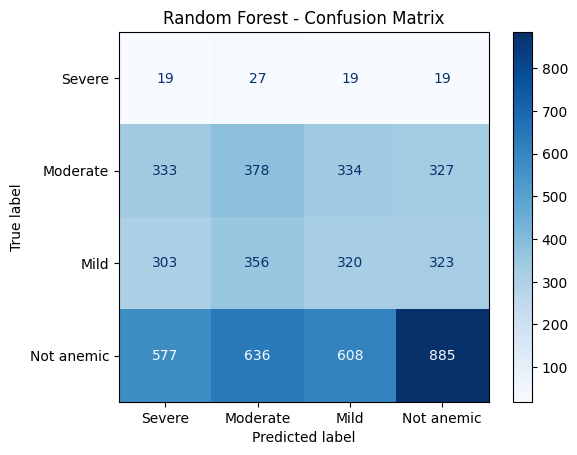

In [29]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict on test data
y_pred_rf = rf_model.predict(X_test)

# Evaluate
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4],
    target_names=[
        "Severe anemia",
        "Moderate anemia",
        "Mild anemia",
        "Not anemic"
    ],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_rf, labels=[1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Severe",
        "Moderate",
        "Mild",
        "Not anemic"
    ]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.show()


XGBoost Accuracy: 0.4896

Classification Report:
                 precision    recall  f1-score   support

  Severe anemia       0.00      0.00      0.00        84
Moderate anemia       0.30      0.07      0.11      1372
    Mild anemia       0.17      0.00      0.00      1302
     Not anemic       0.50      0.95      0.66      2706

       accuracy                           0.49      5464
      macro avg       0.24      0.26      0.19      5464
   weighted avg       0.36      0.49      0.35      5464



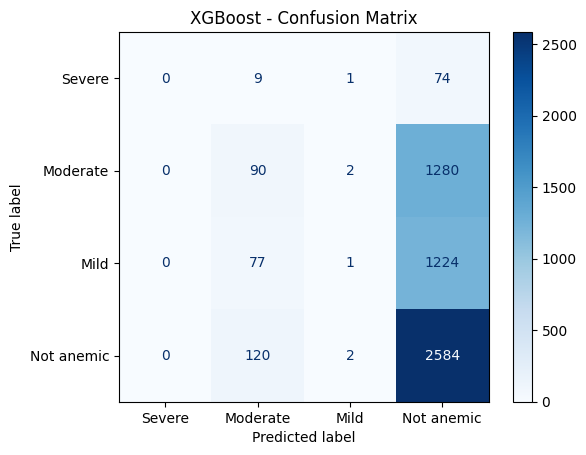

In [30]:

%pip -q install xgboost

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# XGBoost uses class labels 0, 1, 2, 3 internally
y_train_xgb = y_train - 1
y_test_xgb = y_test - 1

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train_xgb)

y_pred_xgb = xgb_model.predict(X_test) + 1

print("XGBoost Accuracy:",
      round(accuracy_score(y_test, y_pred_xgb), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=[1, 2, 3, 4],
    target_names=[
        "Severe anemia",
        "Moderate anemia",
        "Mild anemia",
        "Not anemic"
    ],
    zero_division=0
))

cm_xgb = confusion_matrix(
    y_test, y_pred_xgb, labels=[1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Severe", "Moderate", "Mild", "Not anemic"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost - Confusion Matrix")
plt.show()


In [31]:

# Inspect the metadata retained from the original DHS file
print("Metadata object:", type(meta_subset))

if hasattr(meta_subset, "column_names") and hasattr(meta_subset, "column_labels"):
    print("Metadata columns:", len(meta_subset.column_names))

    metadata_df = pd.DataFrame({
        "variable": meta_subset.column_names,
        "label": meta_subset.column_labels
    })

    keywords = [
        "iron", "supplement", "nutrition", "food",
        "pregnan", "birth", "education", "wealth",
        "water", "sanitation", "diet", "vitamin",
        "deworm", "antenatal", "age"
    ]

    matches = metadata_df[
        metadata_df["label"].fillna("").str.contains(
            "|".join(keywords), case=False, regex=True
        )
    ]

    print("\nPotentially relevant variables:")
    display(matches.head(100))
else:
    print("Full variable metadata is not available in meta_subset.")
    print("Available metadata attributes:")
    print([a for a in dir(meta_subset) if not a.startswith("_")])


Metadata object: <class 'pyreadstat.pyclasses.metadata_container'>
Metadata columns: 8

Potentially relevant variables:


,variable,label
0,v012,respondent's current age
2,v106,highest educational level
3,v190,wealth index combined
4,v213,currently pregnant


In [32]:

# Check which metadata objects are available in the notebook
print("meta_subset columns:", len(meta_subset.column_names))

if "meta" in globals():
    print("Original meta columns:", len(meta.column_names))
else:
    print("No variable named 'meta' is available.")

if "df" in globals():
    print("df shape:", df.shape)
    print("df columns:", df.columns.tolist())
else:
    print("No variable named 'df' is available.")

print("\nCurrent pregnant_df columns:")
print(pregnant_df.columns.tolist())


meta_subset columns: 8
Original meta columns: 5972
df shape: (724115, 8)
df columns: ['v012', 'v025', 'v106', 'v190', 'v213', 'v453', 'v456', 'v457']

Current pregnant_df columns:
['v012', 'v025', 'v106', 'v190', 'v213', 'v453', 'v456', 'v457']


In [33]:

import pandas as pd

# Use the full metadata, not meta_subset
metadata_df = pd.DataFrame({
    "variable": meta.column_names,
    "label": meta.column_labels
})

keywords = [
    "iron", "folic", "supplement", "nutrition",
    "dietary", "food", "vitamin", "anemia", "anaemia",
    "pregnan", "antenatal", "birth", "breastfeed",
    "deworm", "measles", "malaria", "water",
    "sanitation", "cooking", "smoking", "tobacco",
    "age at first", "children ever born",
    "body mass", "height", "weight", "wealth",
    "education", "residence", "hemoglobin", "haemoglobin"
]

pattern = "|".join(keywords)

matches = metadata_df[
    metadata_df["label"].fillna("").str.contains(
        pattern, case=False, regex=True
    )
].copy()

print("Total matching variables:", len(matches))
display(matches.head(150))


Total matching variables: 1516


,variable,label
6,v005,women's individual sample weight (6 decimals)
11,v009,respondent's month of birth
12,v010,respondent's year of birth
13,v011,date of birth (cmc)
28,v025,type of place of residence
...,...,...
382,b11_17,preceding birth interval (months)
383,b11_18,preceding birth interval (months)
384,b11_19,preceding birth interval (months)
385,b11_20,preceding birth interval (months)


In [34]:

# Search full NFHS-5 metadata for relevant candidate predictors

topics = {
    "Iron and nutrition": r"iron|folic acid|vitamin|nutrition|food consumption|dietary diversity|supplement",
    "Pregnancy and antenatal care": r"antenatal|antenatal care|pregnancy|pregnant|prenatal|tetanus",
    "Reproductive history": r"birth interval|children ever born|birth order|age at first birth|births in last five years",
    "Maternal health and anthropometry": r"body mass index|BMI|height|weight|thinness|overweight",
    "Socioeconomic and household": r"wealth index|education|occupation|residence|cooking fuel|drinking water|sanitation"
}

for topic, pattern in topics.items():
    subset = metadata_df[
        metadata_df["label"].fillna("").str.contains(
            pattern, case=False, regex=True
        )
    ]

    print(f"\n--- {topic} ({len(subset)} matches) ---")
    display(subset.head(30))



--- Iron and nutrition (136 matches) ---


,variable,label
1178,m45_1,"during pregnancy, given or bought iron tablets..."
1179,m45_2,"during pregnancy, given or bought iron tablets..."
1180,m45_3,"during pregnancy, given or bought iron tablets..."
1181,m45_4,"during pregnancy, given or bought iron tablets..."
1182,m45_5,"during pregnancy, given or bought iron tablets..."
1183,m45_6,"during pregnancy, given or bought iron tablets..."
1262,m54_1,na - received vitamin a dose in first 2 months...
1263,m54_2,na - received vitamin a dose in first 2 months...
1264,m54_3,na - received vitamin a dose in first 2 months...
1265,m54_4,na - received vitamin a dose in first 2 months...



--- Pregnancy and antenatal care (620 matches) ---


,variable,label
526,b20_01,na - duration of pregnancy
527,b20_02,na - duration of pregnancy
528,b20_03,na - duration of pregnancy
529,b20_04,na - duration of pregnancy
530,b20_05,na - duration of pregnancy
531,b20_06,na - duration of pregnancy
532,b20_07,na - duration of pregnancy
533,b20_08,na - duration of pregnancy
534,b20_09,na - duration of pregnancy
535,b20_10,na - duration of pregnancy



--- Reproductive history (63 matches) ---


,variable,label
126,bord_01,birth order number
127,bord_02,birth order number
128,bord_03,birth order number
129,bord_04,birth order number
130,bord_05,birth order number
131,bord_06,birth order number
132,bord_07,birth order number
133,bord_08,birth order number
134,bord_09,birth order number
135,bord_10,birth order number



--- Maternal health and anthropometry (142 matches) ---


,variable,label
6,v005,women's individual sample weight (6 decimals)
1070,m19_1,birth weight in kilograms (3 decimals)
1071,m19_2,birth weight in kilograms (3 decimals)
1072,m19_3,birth weight in kilograms (3 decimals)
1073,m19_4,birth weight in kilograms (3 decimals)
1074,m19_5,birth weight in kilograms (3 decimals)
1075,m19_6,birth weight in kilograms (3 decimals)
1076,m19a_1,weight at birth/recall
1077,m19a_2,weight at birth/recall
1078,m19a_3,weight at birth/recall



--- Socioeconomic and household (53 matches) ---


,variable,label
28,v025,type of place of residence
29,v026,na - de facto place of residence
45,v102,type of place of residence
46,v103,na - childhood place of residence
47,v104,years lived in place of residence
48,v105,na - type of place of previous residence
49,v105a,na - region of previous residence
50,v106,highest educational level
51,v107,highest year of education
52,v113,source of drinking water


In [35]:

candidate_vars = [
    "v012", "v025", "v106", "v190",
    "v133", "v104", "v208", "v212",
    "v219", "v225", "v214", "v445"
]

metadata_lookup = metadata_df.set_index("variable")

for var in candidate_vars:
    if var in metadata_lookup.index:
        print(f"{var}: {metadata_lookup.loc[var, 'label']}")
    else:
        print(f"{var}: NOT FOUND")


v012: respondent's current age
v025: type of place of residence
v106: highest educational level
v190: wealth index combined
v133: education in single years
v104: years lived in place of residence
v208: births in last five years
v212: age of respondent at 1st birth
v219: living children + current pregnancy
v225: current pregnancy wanted
v214: duration of current pregnancy
v445: body mass index


In [36]:

import pyreadstat
import zipfile

candidate_vars = [
    "v012", "v025", "v106", "v190", "v133",
    "v104", "v208", "v212", "v219", "v225",
    "v214", "v445", "v213", "v457"
]

# Locate the DHS data file inside the ZIP
with zipfile.ZipFile(zip_path) as z:
    dta_name = next(
        name for name in z.namelist()
        if name.upper().endswith("IAIR7EFL.DTA")
    )

    with z.open(dta_name) as dta_file:
        df_new, meta_new = pyreadstat.read_dta(
            dta_file,
            usecols=candidate_vars
        )

# Keep currently pregnant respondents with a known target
pregnant_new = df_new[
    (df_new["v213"] == 1) & df_new["v457"].notna()
].copy()

print("Dataset shape:", pregnant_new.shape)
print("\nMissing values:")
print(pregnant_new.isnull().sum())
print("\nTarget counts:")
print(pregnant_new["v457"].value_counts().sort_index())


Dataset shape: (27317, 14)

Missing values:
v012        0
v025        0
v104        0
v106        0
v133        0
v190        0
v208        0
v212    11091
v213        0
v214       32
v219        0
v225        0
v445       31
v457        0
dtype: int64

Target counts:
v457
1      421
2     6861
3     6509
4    13526
Name: count, dtype: int64


In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from xgboost import XGBClassifier

# Predictor variables: exclude v213 (constant in this subset)
# and v457 (the target).
feature_cols = [
    "v012", "v025", "v104", "v106", "v133",
    "v190", "v208", "v212", "v219", "v225",
    "v214", "v445"
]

# Add a missingness indicator for age at first birth
X = pregnant_new[feature_cols].copy()
X["v212_missing"] = X["v212"].isna().astype(int)

y = pregnant_new["v457"].astype(int)

# Split before fitting preprocessing to avoid leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_imp, y_train)
rf_pred = rf_model.predict(X_test_imp)

# XGBoost: remap classes 1-4 to 0-3
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_imp, y_train - 1)
xgb_pred = xgb_model.predict(X_test_imp) + 1

# Compare results
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Macro F1": [
        f1_score(y_test, rf_pred, average="macro"),
        f1_score(y_test, xgb_pred, average="macro")
    ],
    "Severe anemia recall": [
        classification_report(
            y_test, rf_pred, labels=[1, 2, 3, 4],
            output_dict=True, zero_division=0
        )["1"]["recall"],
        classification_report(
            y_test, xgb_pred, labels=[1, 2, 3, 4],
            output_dict=True, zero_division=0
        )["1"]["recall"]
    ]
})

display(results.round(4))

print("\nRANDOM FOREST REPORT")
print(classification_report(
    y_test, rf_pred,
    labels=[1, 2, 3, 4],
    target_names=[
        "Severe anemia", "Moderate anemia",
        "Mild anemia", "Not anemic"
    ],
    zero_division=0
))

print("\nXGBOOST REPORT")
print(classification_report(
    y_test, xgb_pred,
    labels=[1, 2, 3, 4],
    target_names=[
        "Severe anemia", "Moderate anemia",
        "Mild anemia", "Not anemic"
    ],
    zero_division=0
))


,Model,Accuracy,Macro F1,Severe anemia recall
0,Random Forest,0.4722,0.2599,0.0
1,XGBoost,0.4974,0.2377,0.0



RANDOM FOREST REPORT
                 precision    recall  f1-score   support

  Severe anemia       0.00      0.00      0.00        84
Moderate anemia       0.34      0.20      0.25      1372
    Mild anemia       0.26      0.11      0.15      1302
     Not anemic       0.53      0.80      0.64      2706

       accuracy                           0.47      5464
      macro avg       0.28      0.28      0.26      5464
   weighted avg       0.41      0.47      0.41      5464


XGBOOST REPORT
                 precision    recall  f1-score   support

  Severe anemia       0.00      0.00      0.00        84
Moderate anemia       0.36      0.21      0.27      1372
    Mild anemia       0.29      0.01      0.03      1302
     Not anemic       0.52      0.89      0.66      2706

       accuracy                           0.50      5464
      macro avg       0.29      0.28      0.24      5464
   weighted avg       0.42      0.50      0.40      5464



In [38]:

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, f1_score, accuracy_score
from xgboost import XGBClassifier
import pandas as pd

# Give greater weight to underrepresented classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train - 1
)

xgb_balanced = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.04,
    min_child_weight=1,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_balanced.fit(
    X_train_imp,
    y_train - 1,
    sample_weight=sample_weights
)

balanced_pred = xgb_balanced.predict(X_test_imp) + 1

print("Accuracy:", round(accuracy_score(y_test, balanced_pred), 4))
print("Macro F1:", round(f1_score(y_test, balanced_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    balanced_pred,
    labels=[1, 2, 3, 4],
    target_names=["Severe anemia", "Moderate anemia", "Mild anemia", "Not anemic"],
    zero_division=0
))


Accuracy: 0.3648
Macro F1: 0.2762

Classification report:
                 precision    recall  f1-score   support

  Severe anemia       0.02      0.23      0.04        84
Moderate anemia       0.32      0.33      0.33      1372
    Mild anemia       0.25      0.18      0.21      1302
     Not anemic       0.61      0.47      0.53      2706

       accuracy                           0.36      5464
      macro avg       0.30      0.30      0.28      5464
   weighted avg       0.44      0.36      0.40      5464



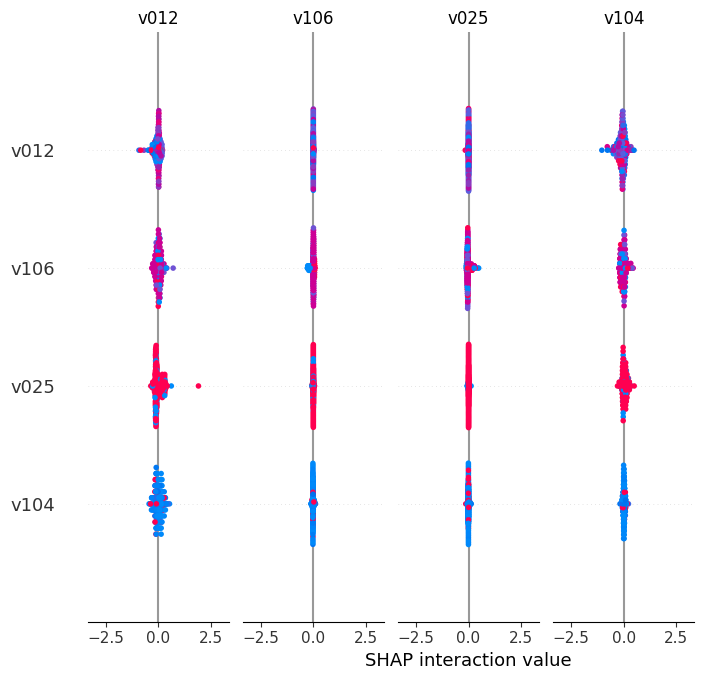

In [39]:

%pip -q install shap

import shap
import matplotlib.pyplot as plt

# Use a manageable sample for explanation
X_shap = X_test_imp.sample(
    n=min(300, len(X_test_imp)),
    random_state=42
)

explainer = shap.TreeExplainer(xgb_balanced)
shap_values = explainer.shap_values(X_shap)

# Summary plot for all classes
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns.tolist(),
    show=True
)


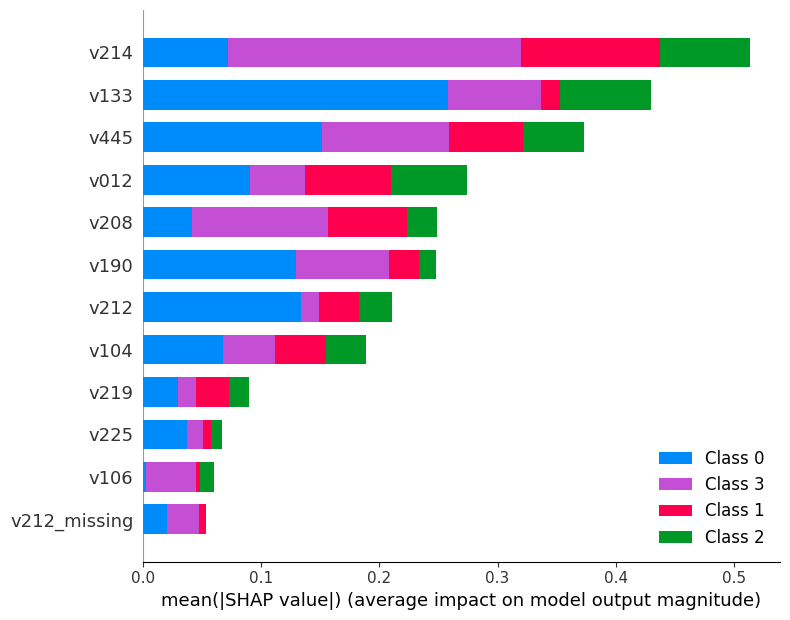

In [40]:
import shap
import matplotlib.pyplot as plt

X_shap = X_test_imp.sample(
    n=min(300, len(X_test_imp)),
    random_state=42
)

explainer = shap.TreeExplainer(xgb_balanced)
shap_values = explainer.shap_values(X_shap)

# Overall feature importance
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=12,
    show=True
)

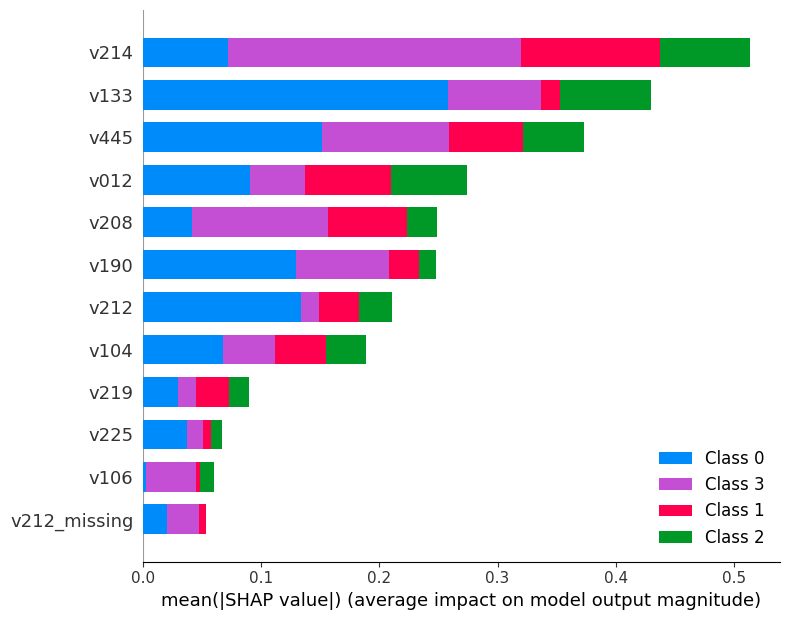

In [41]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=12,
    show=False
)

plt.tight_layout()
plt.savefig("shap_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:

from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

models = {
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "Balanced XGBoost": balanced_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Macro F1": round(
            f1_score(y_test, pred, average="macro", zero_division=0), 4
        ),
        "Severe Anemia Recall": round(
            recall_score(
                y_test, pred, labels=[1], average=None, zero_division=0
            )[0], 4
        ),
        "Moderate Anemia Recall": round(
            recall_score(
                y_test, pred, labels=[2], average=None, zero_division=0
            )[0], 4
        ),
        "Mild Anemia Recall": round(
            recall_score(
                y_test, pred, labels=[3], average=None, zero_division=0
            )[0], 4
        ),
        "Not Anemic Recall": round(
            recall_score(
                y_test, pred, labels=[4], average=None, zero_division=0
            )[0], 4
        )
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Model,Accuracy,Macro F1,Severe Anemia Recall,Moderate Anemia Recall,Mild Anemia Recall,Not Anemic Recall
0,Random Forest,0.4722,0.2599,0.0000,0.2041,0.1052,0.7993
1,XGBoost,0.4974,0.2377,0.0000,0.2085,0.0138,0.8921
2,Balanced XGBoost,0.3648,0.2762,0.2262,0.3345,0.1836,0.4715


In [43]:

import joblib
import os
import pandas as pd
from IPython.display import display, FileLink

# Create a folder for project outputs
os.makedirs("anemia_project_results", exist_ok=True)

# 1. Save model comparison table
comparison_df.to_csv(
    "anemia_project_results/model_comparison.csv",
    index=False
)

# 2. Save the trained balanced XGBoost model
joblib.dump(
    xgb_balanced,
    "anemia_project_results/balanced_xgboost_model.pkl"
)

# 3. Save the preprocessing imputer and feature names
joblib.dump(
    imputer,
    "anemia_project_results/median_imputer.pkl"
)

joblib.dump(
    X_train_imp.columns.tolist(),
    "anemia_project_results/feature_names.pkl"
)

# 4. Save the classification report
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    balanced_pred,
    labels=[1, 2, 3, 4],
    target_names=[
        "Severe anemia",
        "Moderate anemia",
        "Mild anemia",
        "Not anemic"
    ],
    zero_division=0
)

with open(
    "anemia_project_results/classification_report.txt", "w"
) as f:
    f.write(report)

# 5. Save SHAP plot if it was already generated
if os.path.exists("shap_feature_importance.png"):
    import shutil
    shutil.copy(
        "shap_feature_importance.png",
        "anemia_project_results/shap_feature_importance.png"
    )

print("Saved files:")
for filename in os.listdir("anemia_project_results"):
    print("-", filename)

display(comparison_df)


Saved files:
- feature_names.pkl
- classification_report.txt
- balanced_xgboost_model.pkl
- shap_feature_importance.png
- model_comparison.csv
- median_imputer.pkl


,Model,Accuracy,Macro F1,Severe Anemia Recall,Moderate Anemia Recall,Mild Anemia Recall,Not Anemic Recall
0,Random Forest,0.4722,0.2599,0.0000,0.2041,0.1052,0.7993
1,XGBoost,0.4974,0.2377,0.0000,0.2085,0.0138,0.8921
2,Balanced XGBoost,0.3648,0.2762,0.2262,0.3345,0.1836,0.4715


In [44]:

import shutil
import os

folder = "/content/anemia_project_results"
zip_path = "/content/anemia_project_results.zip"

if os.path.exists(folder):
    shutil.make_archive(
        "/content/anemia_project_results",
        "zip",
        folder
    )
    print("ZIP created successfully!")
    print("Files included:", os.listdir(folder))
else:
    print("Results folder not found. Run your save-results cell first.")


ZIP created successfully!
Files included: ['feature_names.pkl', 'classification_report.txt', 'balanced_xgboost_model.pkl', 'shap_feature_importance.png', 'model_comparison.csv', 'median_imputer.pkl']


In [45]:

from google.colab import files

files.download("/content/anemia_project_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>